# Day 2: answering the question

**Python for Data Analysis**, Coding for Reproducible Research (CfRR), University of Exeter

Yesterday we cleaned every month of Oxford weather since 1853 and found that summer 2026 tops the ranking. Today we find out whether that means anything: we plot it, fit a trend and test how sure we can be of it, bring in a second station, combine and resample the two records, and make sure the whole analysis can be rerun by someone else.

## By the end of today you will be able to

- explain why a notebook must run top to bottom from a fresh kernel
- build a matplotlib figure step by step with `fig, ax`, and save it as an image
- make interactive charts with Plotly, and say when each library is the better tool
- say what a NumPy array is, why vectorised code beats a loop, and how `NaN` behaves in NumPy and pandas
- fit a straight-line trend, say how sure you can be of it, and what it cannot tell you
- turn repeated steps into a function, and move it into a `.py` file that any notebook can import
- combine tables with `concat` and `merge`, save them to CSV, reshape them from long to wide, and resample a time series to years or seasons

## How to use this notebook

As yesterday, there are two versions. In `day2.ipynb` most code cells are empty, and you type the code into them as the instructor types it on screen; the few cells that are filled in already, just run. [`day2_solutions.ipynb`](day2_solutions.ipynb), in the same folder, has every cell filled in, with its output: copy any cell you miss from there.

*Data: Met Office historic station data for Oxford and Lerwick. Contains public sector information licensed under the [Open Government Licence v3.0](https://www.nationalarchives.gov.uk/doc/open-government-licence/version/3/).*

> **Instructor: this is your script.** As on Day 1, project the learners' version, `day2.ipynb` from the course zip, and keep this one on a second screen.
>
> **Before 10:00:** everyone activates `.venv`, starts `jupyter lab` and opens `day2.ipynb` from the folder they extracted on Day 1. Nobody needs yesterday's notebook: the first two cells, filled in, redo yesterday's cleaning. The solutions are next to it: `day2_solutions.ipynb`.

## 1. Recap, and "Restart and run all"

*10:00, 10 minutes*

The first two cells are filled in for you. The first imports today's libraries and names the data file and its columns. The second is the whole of yesterday's cleaning in a dozen lines, so everyone starts with the same `oxford` DataFrame. Run them both, then read the second one through: every line is something we did on Day 1.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px

DATA = Path("data")
# Snapshot of https://www.metoffice.gov.uk/pub/data/weather/uk/climate/stationdata/oxforddata.txt
OXFORD = DATA / "oxforddata.txt"
COLUMNS = ["yyyy", "mm", "tmax", "tmin", "af", "rain", "sun", "status"]
MEASURES = ["tmax", "tmin", "af", "rain", "sun"]

In [2]:
oxford = pd.read_csv(OXFORD, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
for col in MEASURES:
    text = oxford[col].astype(str)
    oxford[col + "_estimated"] = text.str.endswith("*")
    oxford[col] = text.str.rstrip("*").astype(float)
oxford["provisional"] = oxford["status"] == "Provisional"
oxford = oxford.drop(columns="status")
oxford["tmean"] = (oxford["tmax"] + oxford["tmin"]) / 2
oxford["date"] = pd.to_datetime({"year": oxford["yyyy"], "month": oxford["mm"], "day": 1})
oxford = oxford.set_index("date")
oxford.shape

(2085, 14)

> **Ten minutes, so keep it moving.** **Do:** scroll through the cleaning cell with the room. **Say:** "This is the whole of yesterday in a dozen lines: read the file, strip the stars and keep them as flags, flag provisional months, add the mean, give every month a date." `oxford.shape` should be `(2085, 14)` for everyone. Green sticky notes when it is.

### The page is not the program

Here are yesterday's summer averages again, in two cells:

In [3]:
summer = oxford[oxford["mm"].isin([6, 7, 8])]

In [4]:
summer_tmax = summer.groupby("yyyy")["tmax"].mean()
summer_tmax.tail(3)

yyyy
2024    21.966667
2025    24.500000
2026    26.166667
Name: tmax, dtype: float64

Now delete the `summer` cell and run the `summer_tmax` cell again. It still works. Then choose **Kernel > Restart Kernel and Run All Cells**, and it fails with `NameError: name 'summer' is not defined`.

The variable `summer` stayed in the kernel's memory after its cell was deleted, so everything kept working until the kernel restarted. A notebook remembers everything you have ever run, in the order you ran it, not the order on the page. The only reliable test is to restart and run everything from the top. Put the missing line back, above the cell that uses it.

> **Slow down.** Do this live in your notebook, then have learners try the same steps (two minutes):
>
> 1. Run the `summer` cell and the `summer_tmax` cell. It works.
> 2. Delete the `summer` cell. Run `summer_tmax` again: it still works.
> 3. **Kernel > Restart Kernel and Run All Cells**: `NameError: name 'summer' is not defined`.
> 4. Put the line back above the cell that uses it.
>
> **Optional:** "Who has had a notebook that worked yesterday and not today?" Plenty of hands.
>
> **Say:** "The kernel remembers everything you've ever run, in the order you ran it. The page is not the program. The only honest test is restart and run all."

## 2. Seeing it

*10:10, 45 minutes*

A matplotlib chart has two main objects: the **Figure** (the whole image) and the **Axes** (one plot inside it, with its own axes, labels and lines). Every chart here starts with `fig, ax = plt.subplots()` and then adds things to `ax`. Writing it this way takes a few more lines than a one-liner, but you control everything. The [CfRR Matplotlib page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/Python_Matplotlib.html) has many more chart types.

Start with every month in the record.

> **About 30 minutes of matplotlib, then 15 of Plotly.**
>
> **Do:** build each chart a line at a time, running the cell after each line, so learners see what each call adds. Start with just `fig, ax = plt.subplots(figsize=(10, 4))` and `plt.show()`: an empty box. **Say:** "That's the Figure, and the box inside it is the Axes. Everything else is adding things to `ax`."
>
> **Watch for:** mixing `plt.plot(...)` with `ax.plot(...)`. Both work, but `plt` draws on "the current axes", which is hidden state again.

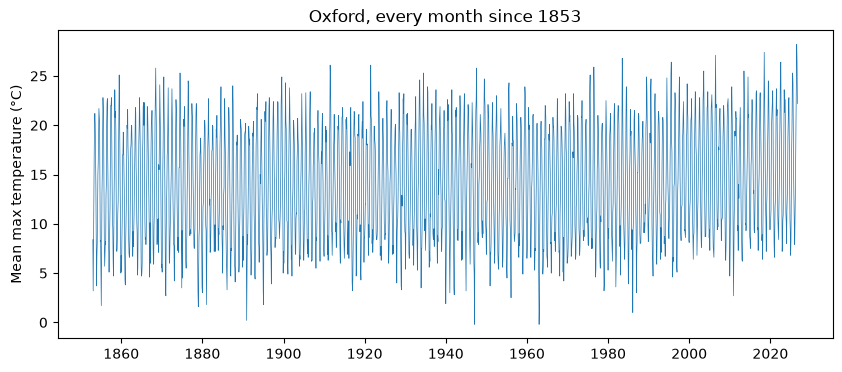

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(oxford.index, oxford["tmax"], linewidth=0.5)
ax.set_ylabel("Mean max temperature (°C)")
ax.set_title("Oxford, every month since 1853")
plt.show()

Unreadable: the seasonal cycle swamps everything else. Choose the chart for the question. Ours is about summers, so plot one value per summer.

(Why not the mean for each calendar year? 2026 only has nine months so far, all from the warmer part of the year, which would flatter it.)

> The monthly chart is unreadable on purpose. **Optional:** ask "What's wrong with this chart?" before fixing it. You want "the seasons swamp everything".

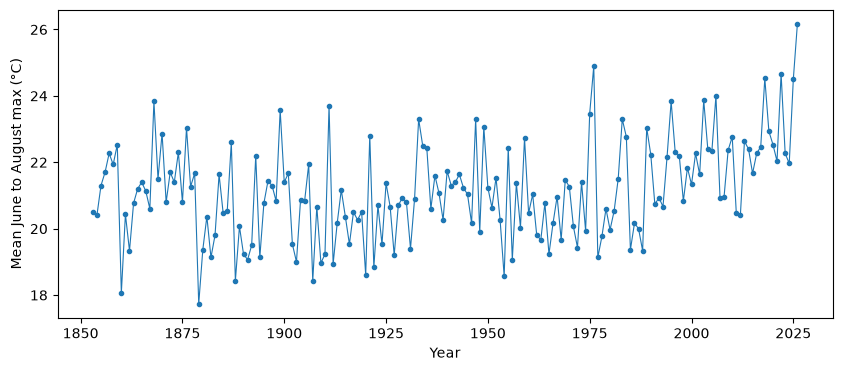

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(summer_tmax.index, summer_tmax, marker=".", linewidth=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
plt.show()

Year-to-year noise hides any slow change. A 10-year rolling mean averages each summer with the nine before it. Add it as a second, thicker line, with a legend to tell them apart.

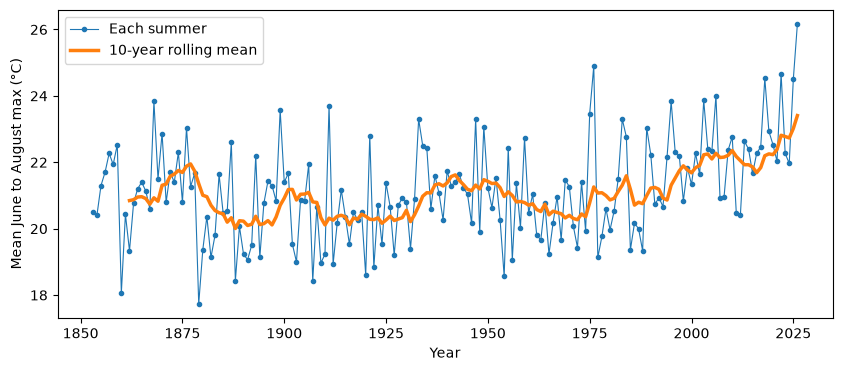

In [7]:
rolling = summer_tmax.rolling(10).mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(summer_tmax.index, summer_tmax, marker=".", linewidth=0.8, label="Each summer")
ax.plot(rolling.index, rolling, linewidth=2.5, label="10-year rolling mean")
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
ax.legend()
plt.show()

Because we kept hold of `ax`, we can keep adding to the same chart. Highlight 2026, then save the figure as a file you could put in a paper.

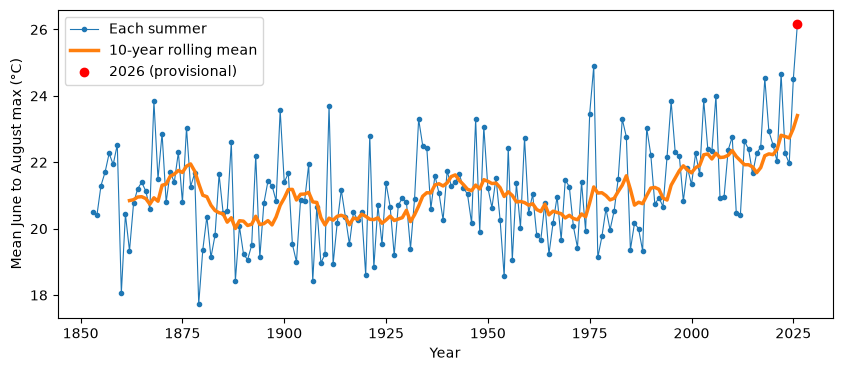

In [8]:
ax.scatter(2026, summer_tmax[2026], color="red", zorder=3, label="2026 (provisional)")
ax.legend()
fig.savefig("summer_tmax.png", dpi=200, bbox_inches="tight")
fig

> This works because `fig` and `ax` still exist after the previous cell; `fig` on the last line redraws it. Show the saved `summer_tmax.png` in the file browser.
>
> `df.plot(ax=ax)` exists and draws onto the same `ax`. Mention it once so learners recognise it in other people's code; don't use it.

### The same thing with Plotly

*Last 15 minutes of this block*

Plotly makes interactive charts that you can hover over, zoom and pan. `plotly.express` builds a whole chart in one call. The [CfRR Plotly page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/data-analysis-plotly.html) goes further.

`px.line` takes a table and the names of its columns. The years are `summer_tmax`'s index, not a column, so `reset_index()` first turns them back into a column, `yyyy`.

In [10]:
px.line(summer_tmax.reset_index(), x="yyyy", y="tmax", markers=True,
        labels={"yyyy": "Year", "tmax": "Mean June to August max (°C)"})

Hover over the points to find the three hottest summers. Drag across the 1970s to zoom in, and double-click to zoom back out.

> **Say:** "One call, and you get hover and zoom for free." Have everyone hover to find the three hottest summers: 2026, 1976, 2022.

Plotly has a function for each kind of chart, all used the same way: a table, then the names of columns. A **box plot** shows how values are spread. The box runs from the 25% value to the 75% value, as in yesterday's `.describe()`, the line across it is the median, and dots beyond the whiskers are unusual months. One box for each month of the year:

In [11]:
px.box(oxford, x="mm", y="tmax", hover_data=["yyyy"],
       labels={"mm": "Month", "tmax": "Mean max temperature (°C)", "yyyy": "Year"})

Hover over the dot above the July box, then the dots above August: `hover_data` adds the year.

Which tool, when?

- **Plotly:** quick to write and good for exploring; charts can be shared as web pages.
- **matplotlib:** more lines of code, but control over every detail, and it saves the static image files that journals want. (Plotly can save static images too, but needs the extra `kaleido` package and a copy of Chrome.)

> July's only unusual month is 2026 (28.2 °C); August's are 1995, 2022 and 2026. The dots under January and February include 1963 and 1947. **Say:** "Same pattern as `px.line`. Learn one Plotly function and you can guess the rest." If time is short, skip it: nothing later needs it.
>
> **Say:** "Plotly for exploring, matplotlib for the figure in your paper." Expect someone to ask which to learn first; the honest answer is matplotlib, because everything else is built on its ideas.

## 3. Is it a trend?

*10:55, 40 minutes*

To fit a trend we use NumPy, the library underneath pandas. First, a look at what it is.

### What's underneath: NumPy

*First 10 minutes of this block*

Every pandas column is a NumPy array with a name and an index attached. NumPy is what makes the arithmetic fast. The [CfRR NumPy page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/Python_NumPy.html) has the full tour.

> **About 10 minutes of NumPy, then 30 on the trend.**

In [12]:
tmax = oxford["tmax"].to_numpy()
tmin = oxford["tmin"].to_numpy()
type(tmax), tmax.dtype, tmax.shape

(numpy.ndarray, dtype('float64'), (2085,))

> `numpy.ndarray`, `float64`, `(2085,)`. **Say:** "Underneath, a column is just this: a block of numbers, all the same type. No names, no index. That's why it's fast."

Yesterday's cleaning, in the second cell of this notebook, gave `oxford` a `tmean` column: the mean temperature for each month, the average of its mean maximum and mean minimum. Here is that calculation the way the Introduction to Python course would write it, with a loop:

In [13]:
tmean_loop = []
for i in range(len(tmax)):
    tmean_loop.append((tmax[i] + tmin[i]) / 2)
tmean_loop[:3]

[np.float64(5.550000000000001),
 np.float64(0.7000000000000001),
 np.float64(3.5500000000000003)]

NumPy can do the same calculation without a loop. Arithmetic on an array applies to every element at once: this is called **vectorisation**.

In [14]:
tmean = (tmax + tmin) / 2
tmean[:3]

array([5.55, 0.7 , 3.55])

Same numbers, less code. It is also much faster. `%timeit` runs a line many times and reports how long it takes:

In [15]:
%timeit [(tmax[i] + tmin[i]) / 2 for i in range(len(tmax))]

240 μs ± 12.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [16]:
%timeit (tmax + tmin) / 2

1.25 μs ± 9.25 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


The vectorised version is many times faster, and the gap grows with the size of the data. That is why pandas and NumPy code avoids looping over rows.

pandas columns work the same way. The cleaning cell made `tmean` with `(oxford["tmax"] + oxford["tmin"]) / 2`, which lines the values up by row, and yesterday's masks, such as `df["tmax"] > 20`, compared every month at once.

> On the instructor laptop: about 230 µs for the loop and 1.3 µs vectorised, roughly 180 times faster. Learners' numbers will differ; the ratio is the point.
>
> **If block 2 overran, skip these two cells** and just say the ratio.

### How NaN behaves

December 1860 has no `tmin`. Here are three ways to average `tmin`, missing month included:

In [17]:
np.mean(tmin)

np.float64(nan)

In [18]:
np.nanmean(tmin)

np.float64(6.280278310940498)

In [19]:
oxford["tmin"].mean()

np.float64(6.280278310940498)

`np.mean` returns `nan`: any arithmetic with `NaN` gives `NaN`, so one missing month spoils the whole result. `np.nanmean` skips missing values. pandas skips them by default, as yesterday's `.count()` showed. Neither choice is wrong, but you need to know which one you are getting.

> `nan`, then 6.28, then 6.28. **Optional:** run them one at a time and take a guess from the room before each.
>
> **Watch for:** "NaN is zero". **Say:** "NaN means unknown. Unknown plus anything is unknown."

### Fitting a straight line

NumPy fits lines too. `np.polyfit(x, y, 1)` finds the straight line that best fits the points (degree 1 means a straight line). It returns the slope and the intercept. Like most NumPy functions, it takes arrays or pandas columns.

In [20]:
slope, intercept = np.polyfit(summer_tmax.index, summer_tmax, 1)
slope * 10  # °C per decade

np.float64(0.09350076406883245)

Positive: summers have been warming. The x values are years, so the slope is in °C per year, and times ten gives °C per decade.

To see the trend, draw it. We will build one chart through the rest of this section, adding each result to it as we go, so keep hold of `fig` and `ax`. A straight line's value in any year is `slope * year + intercept`, and, as with `(tmax + tmin) / 2`, one line of vectorised arithmetic works it out for every year in `summer_tmax.index` at once.

> 0.09 °C per decade from 1853. **Optional:** ask for the sign and rough size of the slope before running it.
>
> **Watch for:** forgetting that `polyfit` gives °C per year. **Say:** "The x values are years, so the slope is per year. Times ten for per decade."
>
> **The next cell starts a chart that grows through the rest of the block.** After each result, add it to the same `ax` and show `fig` again. **Say:** "Every number we get from NumPy and SciPy, we'll put on this chart, so we can see what it means." The labels are the same as block 2's summer chart, so learners can copy them from there.
>
> **Watch for:** running a later chart cell twice, which draws its line twice. To start clean, rerun the cell that makes the figure, then each later chart cell once.

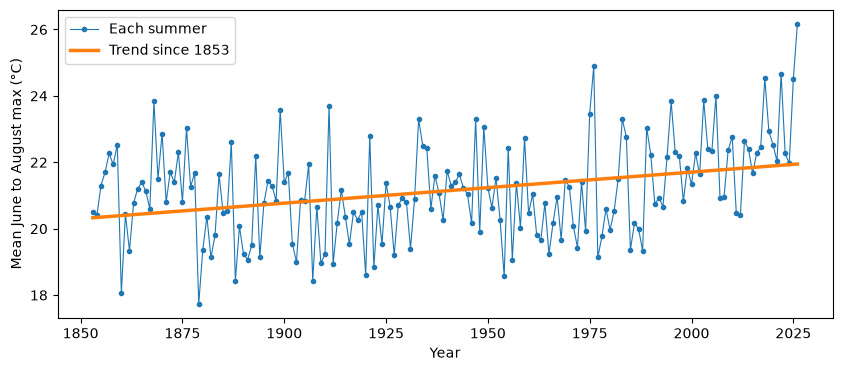

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(summer_tmax.index, summer_tmax, marker=".", linewidth=0.8, label="Each summer")
ax.plot(summer_tmax.index, slope * summer_tmax.index + intercept, linewidth=2.5, label="Trend since 1853")
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
ax.legend()
plt.show()

A single line through every summer since 1853 treats the whole record alike. Fit it again using only summers from 1970 onwards. `summer_tmax` is labelled by year, so `.loc` takes a range of years, as it took a range of dates yesterday: `summer_tmax.loc[1970:]` is every summer from 1970 to the end.

In [22]:
recent = summer_tmax.loc[1970:]
recent_slope, recent_intercept = np.polyfit(recent.index, recent, 1)
recent_slope * 10  # °C per decade

np.float64(0.47024889810733184)

About five times steeper. Add it to the chart: as in block 2, because we kept hold of `ax` we can draw on the same chart again, and `fig` on the last line shows it.

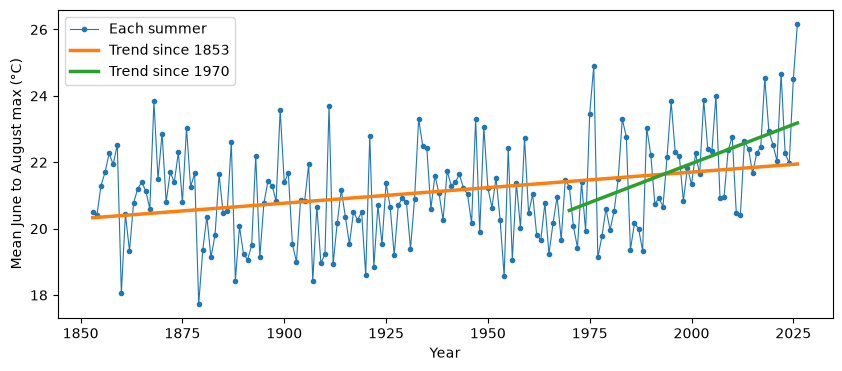

In [23]:
ax.plot(recent.index, recent_slope * recent.index + recent_intercept, linewidth=2.5, label="Trend since 1970")
ax.legend()
fig

A line through every summer since 1853 hides the fact that most of the warming is recent. The start year is a choice, and it changes the answer.

### How sure are we?

A few dozen noisy summers could slope upwards by chance. `scipy.stats.linregress` fits the same straight line as `np.polyfit`, and also says how far to trust it. SciPy, the scientific library built on NumPy, is one of the libraries you installed before the course.

In [24]:
from scipy import stats

fit = stats.linregress(recent.index, recent)
fit.slope * 10, fit.stderr * 10, fit.pvalue, fit.rvalue ** 2

(np.float64(0.4702488981073375),
 np.float64(0.10987736499559357),
 np.float64(7.540476124722002e-05),
 np.float64(0.2498263389189769))

Four numbers, in turn:

- **Slope:** 0.47 °C per decade, the same as `np.polyfit`.
- **Standard error** (`stderr`): how far off the slope could easily be. Roughly, the true rate is within two standard errors of it: here, somewhere between 0.25 and 0.69 °C per decade.
- **p-value:** if summers were not warming at all, how often would chance alone give a slope this steep? Less than once in 10,000, so chance alone is very unlikely to explain it.
- **r²:** the share of the ups and downs from one summer to the next that the line explains. Only a quarter: most of the difference between one summer and the next is weather, not the trend.

> **Slow down on the last two.** 0.47 ± 0.11 °C per decade, p = 0.00008, r² = 0.25.
>
> **Say:** "A tiny p-value says chance alone is very unlikely to explain the trend. A small r² says it explains little about any one summer. Both are true at once, and people mix them up all the time."
>
> **Watch for:** "the p-value is the chance the trend is wrong". It is how surprising a slope this steep would be if there were no trend. Don't go further than that today.
>
> **If asked:** `linregress` assumes each summer is independent of the last. Climate from one year to the next isn't quite, so the true p-value is somewhat larger. It is small enough here not to change the story.
>
> The README's setup installs SciPy beside Plotly, and scikit-learn in the CfRR install brings it too. If the import fails, `pip install scipy`.

The standard error is easier to judge on the chart. A fitted line always passes through the middle of the data: the mean year and the mean temperature. Through that point, draw the shallowest and the steepest lines within two standard errors of the slope, and shade between them. `ax.fill_between(x, lower, upper)` shades the area between two lines; `color="C2"` is matplotlib's third default colour, the green of the 1970 line, and `alpha=0.3` makes the shading see-through.

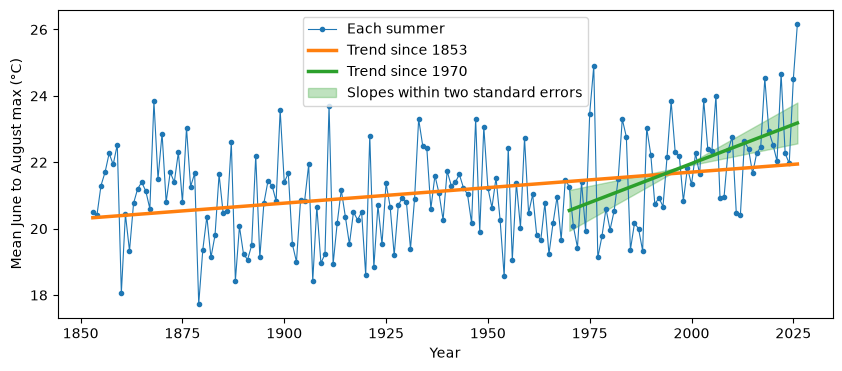

In [25]:
middle = np.mean(recent.index)
low = recent.mean() + (fit.slope - 2 * fit.stderr) * (recent.index - middle)
high = recent.mean() + (fit.slope + 2 * fit.stderr) * (recent.index - middle)
ax.fill_between(recent.index, low, high, color="C2", alpha=0.3, label="Slopes within two standard errors")
ax.legend()
fig

Every line in the fan slopes upwards: that is what the tiny p-value says. The summers themselves scatter far more widely than the fan: that is the small r². We can be fairly sure of the trend and still say little about any one summer.

> **About 5 minutes. If time is short, skip the fan:** nothing later needs it.
>
> **Say:** "Every slope in the green fan goes up: that's the p-value. The dots are all over the place around it: that's the r²." It is the p-value versus r² point from above, as a picture.
>
> **If asked:** the fan is narrowest in the middle because every line in it passes through the mean year and mean temperature, so a change of slope moves the ends most. It is 0.6 °C either side of the line at 1970 and 2026, and about 9 in 10 summers since 1970 fall outside it.

### Unusual for its time?

Summers are warming, so a record is less surprising than it used to be. A fairer question: how far is 2026 from what the recent trend would predict? This cell is filled in, because it has several new ideas at once. Read it a line at a time:

1. fit the line to 1970 to 2025, so 2026 cannot pull the line towards itself
2. use the line to predict 2026
3. measure the typical scatter of summers around the line
4. compare 2026's distance from the line with that scatter

In [26]:
before = summer_tmax.loc[1970:2025]
trend_slope, trend_intercept = np.polyfit(before.index, before, 1)
expected_2026 = trend_slope * 2026 + trend_intercept
scatter = (before - (trend_slope * before.index + trend_intercept)).std()
summer_tmax[2026] - expected_2026, scatter

(np.float64(3.2015800865800905), np.float64(1.2996161851532457))

> From 1970 the slope is 0.47 °C per decade. The 1970 to 2025 line predicts 23.0 °C for 2026; the observed 26.2 °C is 3.2 °C above it, against a typical scatter of 1.3 °C.
>
> **Say:** "So 2026 is about two and a half times further from the trend than a normal summer. Unusual even allowing for the warming." And: "We fitted to 2025, not 2026, so 2026 can't drag the line towards itself."
>
> Talk through the cell a line at a time rather than typing it.

The same comparison on the chart: the 1970 to 2025 line carried on to 2026, dashed, with a grey band one typical scatter either side of it, shaded with `ax.fill_between`. `np.arange(1970, 2027)` makes an array of the years 1970 to 2026 to draw them over. The dotted red line, just `ax.plot` between two points, is the gap between 2026 and the trend. Last, `ax.set_xlim` zooms in on the years since 1960, and the legend, now too long to sit beside the data, moves outside: `bbox_to_anchor=(1, 1)` pins its top-left corner to the top right of the axes.

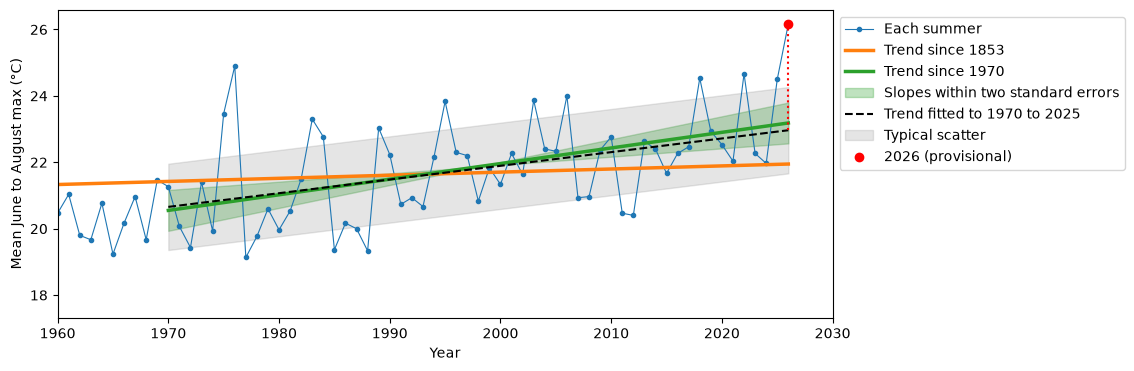

In [27]:
years = np.arange(1970, 2027)
line = trend_slope * years + trend_intercept
ax.plot(years, line, color="black", linestyle="--", label="Trend fitted to 1970 to 2025")
ax.fill_between(years, line - scatter, line + scatter, color="grey", alpha=0.2, label="Typical scatter")
ax.scatter(2026, summer_tmax[2026], color="red", zorder=3, label="2026 (provisional)")
ax.plot([2026, 2026], [expected_2026, summer_tmax[2026]], color="red", linestyle=":")
ax.set_xlim(1960, 2030)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig

> 38 of the 56 summers from 1970 to 2025 sit inside the grey band, about two in three. **Say:** "That's what 'typical scatter' means: most summers land in the band. 2026 isn't close." Point at the dotted line: it is the 3.2 °C from the previous cell.
>
> Point at the end of the dashed line, just under the green one. **Say:** "The green line includes 2026, and 2026 drags it up. That's why we fitted this one to 2025."
>
> If time is short, paste this cell from the solutions rather than typing it.

2026 is about two and a half times as far from the trend as a typical summer. That ratio, the distance from what was expected divided by the typical scatter, is called a **z-score**. If summers scatter round the line in the usual bell-shaped way, fewer than 1 in 100 would land 2.5 or more above it: unusual even allowing for the warming.

What a line can and cannot tell you:

- It **can** summarise the average rate of change over the years you chose.
- It **cannot** tell you why, or promise that the next ten years will follow it.
- 2026 is still **provisional**, and every 2026 temperature is estimated. The Met Office may revise them.

## Break

*11:35, 10 minutes*

## 4. A second station

*11:45, 35 minutes*

Is Oxford typical? Lerwick, in Shetland, is over 900 km further north (60.14°N, 1.18°W, 82 metres above sea level) and surrounded by sea. Its record starts in December 1930.

Yesterday's cleaning steps need to run again for a second file, so we turn them into a function, `load_station(path)`, that returns the cleaned DataFrame, and then move it into a file of its own. You do not need to type it from scratch: copy the cleaning cell from the top of this notebook, add a `def` line, indent everything, call the DataFrame `df` and add `return df`.

> **The tightest block for time.** If you run short, paste the two-station plot from the solutions rather than typing it.
>
> **Do:** copy the cleaning cell from block 1, paste it, add the `def` line, indent everything, rename `oxford` to `df`, add `return df`. **Say:** "Turning working code into a function is mostly copy, paste, indent."
>
> For the fix further down, learners can copy their function into the next empty cell, add the `sun_auto` line and change `"*"` to `"*#"`.

In [28]:
def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = text.str.rstrip("*").astype(float)
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df["date"] = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    df = df.set_index("date")
    return df

Does the function reproduce yesterday's result exactly?

In [29]:
load_station(OXFORD).equals(oxford)

True

> `True`. **Say:** "A function that reproduces yesterday's result is already a check."

Now the second station. Its file is in the `data` folder too:

In [30]:
# Snapshot of https://www.metoffice.gov.uk/pub/data/weather/uk/climate/stationdata/lerwickdata.txt
LERWICK = DATA / "lerwickdata.txt"
LERWICK.exists()

True

In [31]:
lerwick = load_station(LERWICK)

ValueError: could not convert string to float: '222.1#'

Read the error from the bottom up: a sunshine value ending in `#` could not be read. The header of the raw file says what it means. At Lerwick, a `#` after a sunshine value means it came from an automatic sensor rather than the older recorder. Our function was written for Oxford, which never uses `#`.

A loud failure like this is a good thing: it stopped us before anything went wrong.

> `ValueError: could not convert string to float: '222.1#'`. **Do:** open `data/lerwickdata.txt` from the file browser, as on Day 1, and read the header to find what `#` means (Kipp & Zonen automatic sensor).
>
> **Say:** "A loud failure is good news. Our code refused to guess."
>
> **If someone suggests `errors="coerce"`:** it would silence the error and turn all 215 `#` values into `NaN`, yesterday's trap again.

The fix follows yesterday's pattern: strip the `#` as well as the `*`, and keep the information in a `sun_auto` column, just as we kept the estimates. Copy your function into the next cell, add one line and change another:

In [32]:
def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    df["sun_auto"] = df["sun"].astype(str).str.endswith("#")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = text.str.rstrip("*#").astype(float)
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df["date"] = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    df = df.set_index("date")
    return df

In [33]:
lerwick = load_station(LERWICK)
lerwick["sun"].isna().sum(), lerwick["sun_auto"].sum()

(np.int64(0), np.int64(215))

> `(0, 215)`: no sunshine lost, and 215 Lerwick months flagged as automatic. **Say:** "Same pattern as yesterday: keep the flag, strip the marker, fail loudly on anything else."

### Moving the function into a file

`load_station` works now, but a function defined in a notebook only exists in that notebook, and only once its cell has run. Code you want to reuse belongs in a `.py` file next to the notebook, which any notebook or script in the folder can `import`, just as we import pandas.

`%%writefile helper.py`, on the first line of a cell, saves the rest of the cell to a file called `helper.py` instead of running it. A `.py` file can't see the notebook's variables, so it needs its own `import pandas as pd`, and the `COLUMNS` and `MEASURES` lists the function uses. Type the first two lines, copy `COLUMNS` and `MEASURES` from the top of the notebook, then paste your last `load_station` underneath.

In [34]:
%%writefile helper.py
import pandas as pd

COLUMNS = ["yyyy", "mm", "tmax", "tmin", "af", "rain", "sun", "status"]
MEASURES = ["tmax", "tmin", "af", "rain", "sun"]


def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    df["sun_auto"] = df["sun"].astype(str).str.endswith("#")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = text.str.rstrip("*#").astype(float)
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df["date"] = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    df = df.set_index("date")
    return df

Writing helper.py


Open `helper.py` from the file browser: an ordinary text file, with nothing notebook-specific in it. Now import the function from it. The import replaces the `load_station` defined in this notebook, so load both stations again with the imported one:

In [35]:
from helper import load_station

oxford = load_station(OXFORD)
lerwick = load_station(LERWICK)
oxford.shape, lerwick.shape

((2085, 15), (1150, 15))

> **About 5 minutes.** **Do:** open `helper.py` from the file browser once the cell has run. **Say:** "That's a module. Any notebook in this folder can now say `from helper import load_station`, and there's one copy of the cleaning to fix, not one per notebook." The shapes are `(2085, 15)` and `(1150, 15)`: `sun_auto` is the extra column.
>
> **Watch for:** editing `helper.py` after importing it. Python reads a module once per kernel, so running the import again does not pick up the change. Restart the kernel and run from the top.
>
> **If asked** why we don't just `%run` yesterday's notebook: it runs all of it and leaves every one of its variables in ours, without saying which, the hidden state from block 1 again. An import takes only the names you ask for.

### Stacking the stations

To compare the stations, stack them into one table with a `station` column. `pd.concat` puts tables on top of each other, and `.assign` adds a column with the same value in every row. The result is **long** data: one row per station per month. Long data suits `groupby`.

In [36]:
both = pd.concat([oxford.assign(station="Oxford"), lerwick.assign(station="Lerwick")])
both.groupby("station")["tmax"].mean()

station
Lerwick     9.548522
Oxford     14.029113
Name: tmax, dtype: float64

`both` is worth keeping: the cleaned records of both stations in one table. `.to_csv` writes a DataFrame or Series to a CSV file, which opens in anything from Python to Excel, so a colleague can use the cleaned data without running any of this:

In [ ]:
both.to_csv("both_stations.csv")

> No output. **Do:** open `both_stations.csv` from the file browser: 3235 rows, the dates, which were the index, are the first column, and the `station` column says which record each row came from. **Say:** "Save the cleaned data, not just the charts made from it. The flag columns go too, so whoever opens it can still see which values were estimated."
>
> **If asked** about `tmean` values like `5.550000000000001`: computers store most decimals slightly inaccurately. `both.round(2).to_csv(...)` hides it.

Now the summer mean max for both stations, on one `ax`. Was 2026 a record summer in Lerwick too?

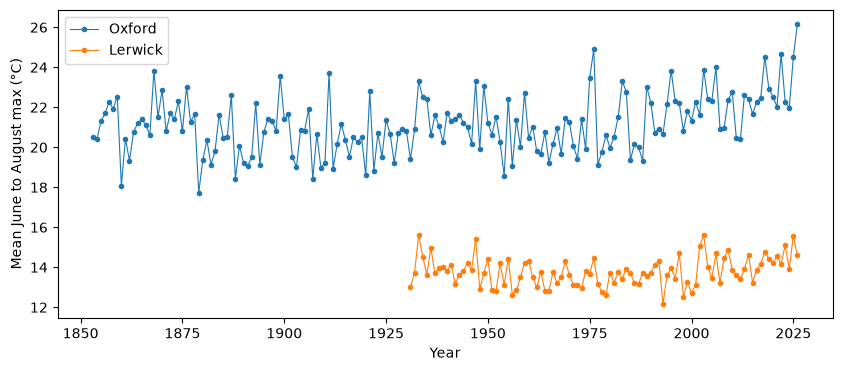

In [37]:
summers = both[both["mm"].isin([6, 7, 8])].groupby(["station", "yyyy"])["tmax"].mean()
fig, ax = plt.subplots(figsize=(10, 4))
for station in ["Oxford", "Lerwick"]:
    ax.plot(summers[station].index, summers[station], marker=".", linewidth=0.8, label=station)
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
ax.legend()
plt.show()

In [38]:
summers["Lerwick"].sort_values(ascending=False).head(3)

yyyy
1933    15.600000
2003    15.600000
2025    15.566667
Name: tmax, dtype: float64

No. 2026 is not even in Lerwick's top three summers. The heat of 2026 was a southern story, which is exactly why one station is not enough to talk about "the UK".

> Mean `tmax` over the whole record: Oxford 14.0 °C, Lerwick 9.5 °C.
>
> Lerwick's top three summers: 1933 and 2003 at 15.6 °C, 2025 at 15.57 °C. 2026 was 14.6 °C. **Say:** "The 2026 heat was a southern story."

## 5. Combining and resampling

*12:20, 30 minutes*

`both` is long: the stations stacked, one row per station per month. To read the stations side by side, **wide** data is easier: one column per station. There are two ways to get there, `unstack` and `merge`.

### From long to wide

`summers` has two levels of labels in its index, station and year. `unstack` moves the `station` level into the columns. You will also meet `pivot`, which does the same job starting from ordinary columns, and `melt`, which goes the other way, from wide back to long.

In [39]:
wide = summers.unstack("station")
wide.tail(3)

station,Lerwick,Oxford
yyyy,,
2024,13.933333,21.966667
2025,15.566667,24.500000
2026,14.600000,26.166667


Do the two stations have their hot summers in the same years? `.corr()` gives the **correlation** between each pair of columns: 1 means they rise and fall together exactly, 0 means no connection, and -1 means one rises as the other falls.

In [40]:
wide.corr().round(2)

station,Lerwick,Oxford
station,,
Lerwick,1.00,0.56
Oxford,0.56,1.00


0.56: a hot summer in Oxford tends to be a warm one in Lerwick, but only loosely. A scatter plot shows what that looks like. Hover over the point furthest to the right:

In [41]:
px.scatter(wide, x="Oxford", y="Lerwick", hover_name=wide.index,
           labels={"Oxford": "Oxford summer max (°C)", "Lerwick": "Lerwick summer max (°C)"})

2026 is far to the right, but only halfway up: the southern story again.

### Side by side by date: `merge`

`unstack` worked because both stations were already in one table. `merge` lines up two separate tables wherever their **key** columns match, here the year and the month. Columns with the same name in both tables get a suffix to tell them apart:

In [42]:
side = oxford.merge(lerwick, on=["yyyy", "mm"], suffixes=("_oxford", "_lerwick"))
side[["yyyy", "mm", "tmax_oxford", "tmax_lerwick"]].head(3)

,yyyy,mm,tmax_oxford,tmax_lerwick
0,1930,12,7.0,7.0
1,1931,1,6.5,4.9
2,1931,2,7.4,4.4


It starts in December 1930, not 1853. By default `merge` keeps only the months that are in both tables: an **inner** join. `how="left"` keeps every row of the left table, Oxford, and leaves Lerwick's columns missing before 1930. Count the rows each way:

In [43]:
len(side), len(oxford.merge(lerwick, on=["yyyy", "mm"], how="left"))

(1150, 2085)

Which rows survive is a decision, like `dropna` yesterday. With the stations side by side, one subtraction compares them month by month. How much warmer are Oxford's days than Lerwick's, at each time of year?

In [44]:
side["gap"] = side["tmax_oxford"] - side["tmax_lerwick"]
side.groupby("mm")["gap"].mean().round(1)

mm
1     1.5
2     2.4
3     4.2
4     5.5
5     6.6
6     7.6
7     8.1
8     7.5
9     6.2
10    4.4
11    2.5
12    1.5
Name: gap, dtype: float64

1.5 °C in December and January, but 8.1 °C in July. The sea round Shetland is slow to warm and slow to cool, so Lerwick's summers stay cool and its winters mild.

> Lerwick's summers correlate 0.56 with Oxford's. `side` has 1150 rows (every Lerwick month, from December 1930); the left join has 2085 (every Oxford month).
>
> **Say:** "`concat` puts tables on top of each other; `merge` puts them next to each other, matched on a key."
>
> **Watch for:** leaving out `on`. `merge` then matches on every column the two tables share, temperatures included, and gives an empty table: 0 rows.

### Resampling: months into years and seasons

Yesterday, `groupby("yyyy")` needed a year column. With dates as the index, `resample` groups by time directly. `"YE"` means calendar years, each labelled by its last day. Total rainfall for each year:

In [45]:
annual_rain = oxford["rain"].resample("YE").sum()
annual_rain.tail(3)

date
2024-12-31    915.8
2025-12-31    580.9
2026-12-31    242.6
Freq: YE-DEC, Name: rain, dtype: float64

2026 looks like a drought, but it has only nine months so far. `.count()` shows how many months went into each total:

In [46]:
oxford["rain"].resample("YE").count().tail(3)

date
2024-12-31    12
2025-12-31    12
2026-12-31     9
Freq: YE-DEC, Name: rain, dtype: int64

A part-year gives a misleading total or average, which is why we compare summers rather than years. `resample` makes seasons too. `"QS-DEC"` cuts the year into quarters starting in December, so they are winter (December to February), spring, summer and autumn, each labelled by its first month. The coldest winters:

In [47]:
seasons = oxford["tmax"].resample("QS-DEC").mean()
winters = seasons[seasons.index.month == 12]
winters.sort_values().head(3)

date
1962-12-01    1.900000
1878-12-01    3.566667
1946-12-01    3.633333
Name: tmax, dtype: float64

The coldest is the winter of 1962 to 1963, the Big Freeze, labelled by its December. The quarters labelled June are our summers, made a second way. Two routes to the same numbers is a good check:

In [48]:
np.allclose(seasons[seasons.index.month == 6], summer_tmax)

True

> Annual rain: 915.8 mm in 2024, 580.9 mm in 2025, 242.6 mm for the nine months of 2026. The coldest winters: 1962 to 1963 at 1.9 °C, then 1878 to 1879 and 1946 to 1947 at 3.6 °C. The `allclose` check gives `True`.
>
> The first quarter, December 1852, holds only January and February 1853, and the last holds only September 2026: the part-year problem again. **Optional:** ask why `winters` might be unfair at either end.
>
> **If time is short,** skip the scatter plot and the `allclose` check.

## 6. Wrap: so, was summer 2026 unusual?

*12:50, 10 minutes*

This cell, filled in, pulls the numbers together:

In [49]:
previous = summer_tmax.drop(2026)
print(f"Summer 2026 mean max: {summer_tmax[2026]:.1f} °C")
print(f"Previous record: {previous.max():.1f} °C in {previous.idxmax()}")
print(f"Above the 1970 to 2025 trend by {summer_tmax[2026] - expected_2026:.1f} °C")
print(f"Typical scatter around the trend: {scatter:.1f} °C")
print(f"z-score: {(summer_tmax[2026] - expected_2026) / scatter:.1f}")

Summer 2026 mean max: 26.2 °C
Previous record: 24.9 °C in 1976
Above the 1970 to 2025 trend by 3.2 °C
Typical scatter around the trend: 1.3 °C
z-score: 2.5


So what would we write, in one sentence, and which caveats belong in it? One version:

> Summer 2026 was the hottest in Oxford's record, which goes back to 1853, by more than a degree, and well above what even the recent warming trend would predict; the figures are still provisional, and the analysis should be rerun on a later snapshot once the Met Office confirms them.

> **Optional:** go back to the guesses and "what would convince you?" from 10:00 on Day 1. Did today's numbers convince them? Take a sentence from the room before showing the suggested one, and push for the caveats: provisional, estimated, one station.

### Reproducibility checklist

- **Pinned data:** a dated snapshot of the Met Office files, kept with the notebooks; [`data/README.md`](data/README.md) records where each file came from and its checksum.
- **Locked libraries:** `uv.lock` records exact versions; `requirements.txt` is exported from it for pip users.
- **Fresh kernel:** the notebook runs top to bottom after a restart.
- **Flags kept:** estimated, provisional and automatic-sensor values are marked, not dropped.
- **Checks:** count rows and missing values before and after each step, so a silent mistake shows up when the code meets new data.
- **Shared code in a file:** `load_station` lives in `helper.py`, imported wherever it is needed rather than copied between notebooks.

### Demo: uv (optional)

uv is a fast replacement for `pip` and `venv`. In a copy of the course repository:

```bash
uv sync             # create .venv with exactly the versions in uv.lock
uv run jupyter lab  # start JupyterLab inside that environment
uv add seaborn      # add a library and update the lock file
```

If you prefer pip, `pip install -r requirements.txt` gives you the same versions.

### Where next

- [Introduction to Machine Learning](https://coding-for-reproducible-research.github.io/CfRR_Courses/programme_information/introduction_to_machine_learning.html), for models that learn from data
- [Python Checking and Testing Code](https://coding-for-reproducible-research.github.io/CfRR_Courses/short_courses/python_testing.html), for turning checks like ours into tests that run every time
- [Version Control](https://coding-for-reproducible-research.github.io/CfRR_Courses/programme_information/version_control.html)

> **uv demo, 2 to 3 minutes, in a terminal:** `uv sync`, `uv run jupyter lab`, then `uv add seaborn` and show the diff in `uv.lock` (`git diff uv.lock`). **Say:** "The lock file records the exact version of everything. `requirements.txt` is the pip-friendly export of the same thing. Try uv if you like; pip is fine." Undo afterwards with `git checkout pyproject.toml uv.lock`.
>
> Finish by pointing to the three CfRR courses above.